## Implementing algorithm 1 from the paper. 
Computing omega points for the 3vs1 case
including the functions to check if points are in a good position 


In [3]:
import gudhi
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import matplotlib
from math import cos, sin, pi, atan     
import itertools
# from scipy.stats import qmc
import math

import numpy.linalg

## for checking if in convex hull
import scipy.spatial
from scipy.optimize import linprog

import sys 
sys.path.append('../Code/')
import modules as mod
import examples as ex
import plot as ourplot
import csv

import omega_pts as omega
# This reloads external modules every time a cell is run
# so we don't have to reboot kernel every time we modify classes.py
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Note to selves: both 2:2 and 3:1 still need that we remove omega pts if they are already crit pts

Also note to self: needed to say CritPts[a].coords instead of CritPts[a] here for checking 4 distinct to actually work. Should we update elsewhere? check.

### Example 2.12 : infinite modules

In [6]:
CritPts = ex.example_2_12()
CritPts
name = "Example_2_12"

In [13]:
# run algo 3v1 
Pts = omega.output_alg_3_1(CritPts, name)
print(Pts)

**********
Computed 2 points (with duplicates)
Without duplicates 1
([(2.0, 4.0)], 2, 1)


In [14]:
# run algo 2v2 paired 
Pts = omega.output_alg_2_2_paired(CritPts, name)
print(Pts)


**********
Computed 0 points (with duplicates)
Without duplicates 0
([], 0, 0, ['m'], ['omega_pts'])


In [15]:
# run algo 2v2 unpaired
Pts = omega.output_alg_2_2_unpaired(CritPts, name)
print(Pts)


**********
Computed 0 points (with duplicates)
Without duplicates 0
([], 0, 0, ['m'], ['omega_pts'])


../Code/omega_pts.py:35: OptimizeWarning: A_eq does not appear to be of full row rank. To improve performance, check the problem formulation for redundant equality constraints.
  b_eq=b,


## Test example for algo 2v2 unpaired 

In [7]:
CritPts = ex.test_example()
CritPts

[(parent module of (0.0, 0.0) is 0),
 (parent module of (7.0, 0.0) is 0),
 (parent module of (0.0, 4.0) is 0),
 (parent module of (3.0, 2.0) is 1),
 (parent module of (3.0, 6.0) is 1),
 (parent module of (10.0, 2.0) is 1)]

In [8]:
omega_test = omega.output_alg_2_2_unpaired(CritPts, 'Test')

../Code/omega_pts.py:35: OptimizeWarning: A_eq does not appear to be of full row rank. To improve performance, check the problem formulation for redundant equality constraints.
  b_eq=b,


**********
Computed 20 points (with duplicates)
Without duplicates 16


## Examples from the paper

### Example 2.13, figure 3

$M = [0,7)\times [0,8) \cup [0,7)\times [4,11)$ and $N = [0,7)\times [0,11) \cup [0,7)\times [4,8)$

In [9]:
CritPts = ex.example_2_13()
CritPts

[(parent module of (0.0, 0.0) is 0),
 (parent module of (7.0, 0.0) is 0),
 (parent module of (0.0, 4.0) is 0),
 (parent module of (7.0, 4.0) is 0),
 (parent module of (0.0, 8.0) is 0),
 (parent module of (0.0, 11.0) is 0),
 (parent module of (0.0, 0.0) is 1),
 (parent module of (7.0, 0.0) is 1),
 (parent module of (0.0, 4.0) is 1),
 (parent module of (7.0, 4.0) is 1),
 (parent module of (0.0, 8.0) is 1),
 (parent module of (0.0, 11.0) is 1)]

In [10]:
Omega_2v2_unpaired = omega.output_alg_2_2_unpaired(CritPts, 'Example_2.13')

**********
Computed 325 points (with duplicates)
Without duplicates 40


../Code/omega_pts.py:35: OptimizeWarning: Solving system with option 'cholesky':True failed. It is normal for this to happen occasionally, especially as the solution is approached. However, if you see this frequently, consider setting option 'cholesky' to False.
  b_eq=b,
../Code/omega_pts.py:35: OptimizeWarning: Solving system with option 'sym_pos':True failed. It is normal for this to happen occasionally, especially as the solution is approached. However, if you see this frequently, consider setting option 'sym_pos' to False.
  b_eq=b,
/Users/celiahacker/opt/anaconda3/envs/celia/lib/python3.7/site-packages/scipy/optimize/_linprog_ip.py:117: LinAlgWarning: Ill-conditioned matrix (rcond=2.02115e-18): result may not be accurate.
  return sp.linalg.solve(M, r, sym_pos=sym_pos)
../Code/omega_pts.py:35: OptimizeWarning: Solving system with option 'sym_pos':False failed. This may happen occasionally, especially as the solution is approached. However, if you see this frequently, your problem

**********
Computed 1490 points (with duplicates)
Without duplicates 57


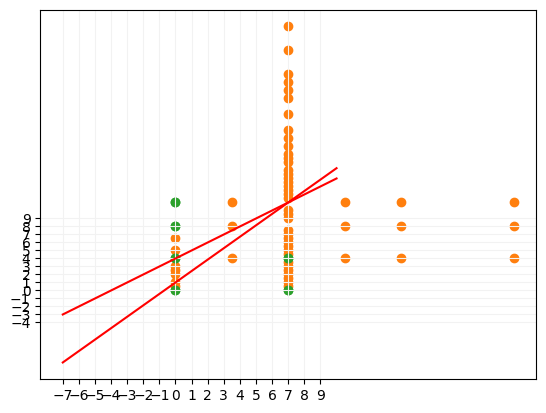

In [11]:
CritPts = ex.example_2_13()
name = "2_13"
Pts = omega.output_alg_3_1(CritPts, name)
ourplot.plotmod(CritPts, Pts)

In [13]:
Omega_pts = omega.output_alg_2_2_paired(CritPts, 'Example_2.13')

**********
Computed 136 points (with duplicates)
Without duplicates 12


### Example 2.11

$M = [0,7)\times [0,7) \cup [0,7)\times [4,11)$ and $N = [0,7)\times [0,11) \cup [0,7)\times [4,7)$

../Code/omega_pts.py:35: OptimizeWarning: A_eq does not appear to be of full row rank. To improve performance, check the problem formulation for redundant equality constraints.
  b_eq=b,
../Code/omega_pts.py:35: OptimizeWarning: Solving system with option 'cholesky':True failed. It is normal for this to happen occasionally, especially as the solution is approached. However, if you see this frequently, consider setting option 'cholesky' to False.
  b_eq=b,
../Code/omega_pts.py:35: OptimizeWarning: Solving system with option 'sym_pos':True failed. It is normal for this to happen occasionally, especially as the solution is approached. However, if you see this frequently, consider setting option 'sym_pos' to False.
  b_eq=b,
../Code/omega_pts.py:35: OptimizeWarning: Solving system with option 'sym_pos':False failed. This may happen occasionally, especially as the solution is approached. However, if you see this frequently, your problem may be numerically challenging. If you cannot improve 

**********
Computed 1472 points (with duplicates)
Without duplicates 52


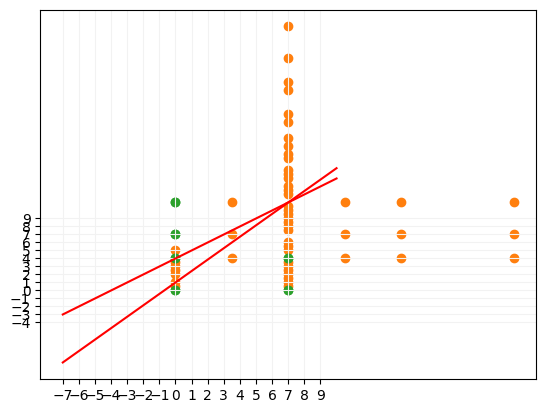

In [14]:
CritPts = ex.example_2_11()
name = "2_11"
Pts = omega.output_alg_3_1(CritPts, name)
ourplot.plotmod(CritPts, Pts)

In [15]:
CritPts = ex.example_2_11()
Omega_pts = omega.output_alg_2_2_paired(CritPts, 'Example_2.11')

**********
Computed 144 points (with duplicates)
Without duplicates 12


In [16]:
CritPts = ex.example_2_11()
Omega_pts = omega.output_alg_2_2_unpaired(CritPts, 'Example_2.11')

../Code/omega_pts.py:35: OptimizeWarning: A_eq does not appear to be of full row rank. To improve performance, check the problem formulation for redundant equality constraints.
  b_eq=b,


**********
Computed 324 points (with duplicates)
Without duplicates 43


### Example 1
$M=[0,7]\times[0,8]$ and $N=[1,8]\times[1,9]$

**********
Computed 108 points (with duplicates)
Without duplicates 37


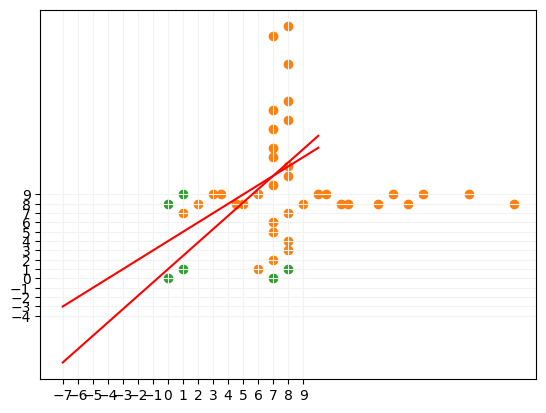

In [17]:
CritPts = ex.example_1()
name = "1"
Pts = omega.output_alg_3_1(CritPts, name)
ourplot.plotmod(CritPts, Pts)

In [18]:
CritPts = ex.example_1()
Omega_pts = omega.output_alg_2_2_paired(CritPts, 'Example_1_2v2')

**********
Computed 16 points (with duplicates)
Without duplicates 12


### Example 2 
$M=[0,4]\times[0,4]$ and $N=[1,3]\times[0,4]$

Should have $(1,1),(2,2),(3,3)$ as $\Omega$-pts

**********
Computed 66 points (with duplicates)
Without duplicates 15


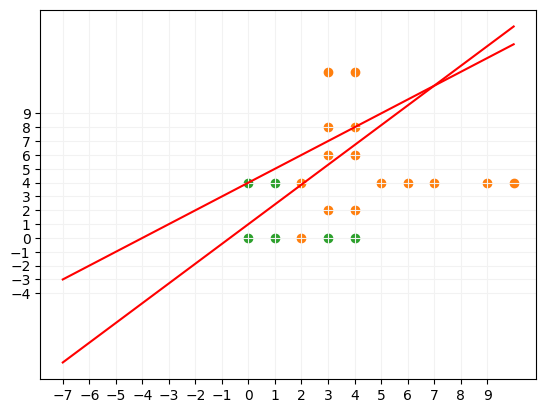

In [19]:
CritPts = ex.example_2()
name = "2"
Pts = omega.output_alg_3_1(CritPts, name)
ourplot.plotmod(CritPts, Pts)


In [20]:
CritPts = ex.example_2()
Omega_pts = omega.output_alg_2_2_paired(CritPts, 'Example_2')

**********
Computed 8 points (with duplicates)
Without duplicates 6


In [21]:
CritPts = ex.example_2()
Omega_pts = omega.output_alg_2_2_unpaired(CritPts, 'Example_2')

**********
Computed 25 points (with duplicates)
Without duplicates 21


###### remark: in this example we should not need the omega pts on the boundary of the support 